# Day 024 | Matplotlib — Subplots & Customization

## 100 Days of ML for Geotechnical Engineering
**Phase:** Data Science Essentials

**Author:** Ripon Chandra Malo  
**Date:** 2026-03-01  

---

## What We Will Learn Today

| Concept | What It Means | Geotechnical Example |
|---------|--------------|---------------------|
| `plt.subplots(rows, cols)` | Multi-panel figure layout | Side-by-side borehole profiles |
| `fig.add_subplot()` | Add panels to existing figure | Building a report sheet panel by panel |
| Colors, markers, styles | Visual differentiation | Soil type color coding |
| `ax.annotate()` | Text arrows pointing at data | Labeling critical layers |
| `ax.text()` | Floating text boxes | Adding soil descriptions |
| Axis limits & ticks | Control what range is shown | Setting depth range 0-20m |
| `plt.savefig()` | Export to PNG, PDF, SVG | Figures for reports and papers |
| Shared axes | Same scale across panels | Consistent depth axis for comparison |

---

## Our Geotechnical Problem

A single borehole generates **multiple types of data**: N-values, soil descriptions, shear wave velocity, and computed overburden pressures. Engineers present these as a **multi-panel summary sheet** — one row of panels sharing the same depth axis.

Today we build that summary sheet using `plt.subplots()`, and learn every customization tool needed to make publication-quality geotechnical figures.

---

## Part 1: Creating Subplots — `plt.subplots()`

The `plt.subplots(nrows, ncols)` function creates a **figure** and a **grid of axes** (panels) in one call.

```python
fig, axes = plt.subplots(1, 2)  # 1 row, 2 columns
# axes[0] = left panel
# axes[1] = right panel

fig, axes = plt.subplots(2, 2)  # 2 rows, 2 columns
# axes[0, 0] = top-left    axes[0, 1] = top-right
# axes[1, 0] = bottom-left axes[1, 1] = bottom-right
```

The key difference from Day 023: instead of `plt.plot()`, we use `axes[i].plot()` to target a specific panel.

In [1]:
# ─────────────────────────────────────────────────────
# IMPORTS
# ─────────────────────────────────────────────────────

%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

print("Matplotlib ready for subplots!")

Matplotlib ready for subplots!


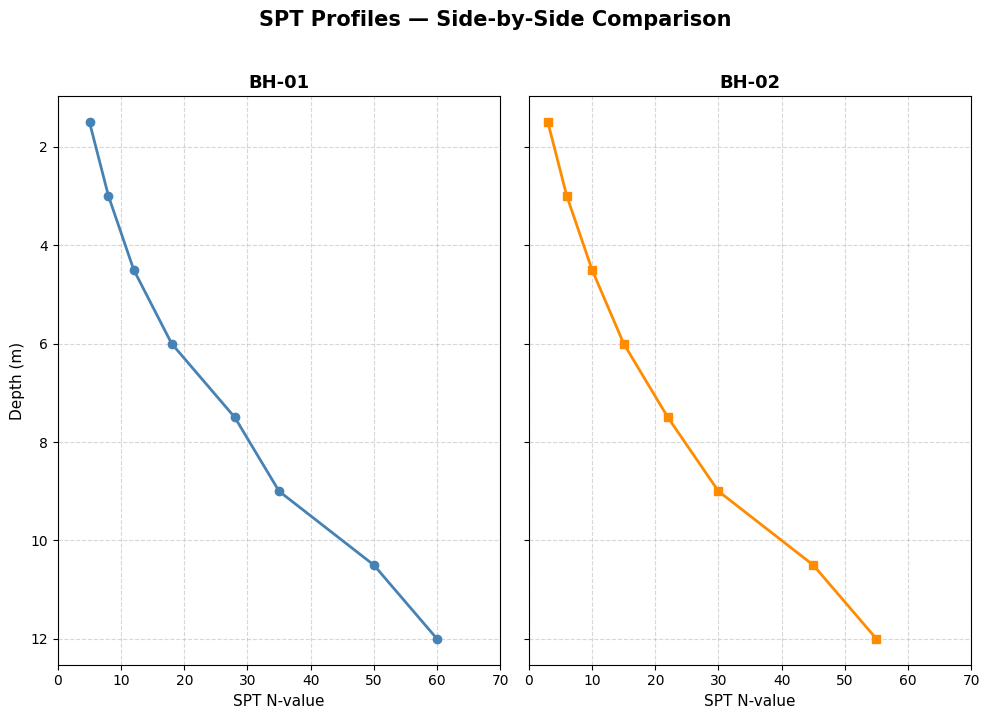

sharey=True keeps the same depth scale on both panels.
Each ax object controls one panel independently.


In [2]:
# ─────────────────────────────────────────────────────
# BASIC SUBPLOTS — Two boreholes side by side
# ─────────────────────────────────────────────────────

depth_m  = [1.5, 3.0, 4.5, 6.0, 7.5, 9.0, 10.5, 12.0]
n_bh01   = [5, 8, 12, 18, 28, 35, 50, 60]
n_bh02   = [3, 6, 10, 15, 22, 30, 45, 55]

# Create 1 row, 2 columns — shared y-axis (same depth scale)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 7), sharey=True)

# Left panel: BH-01
ax1.plot(n_bh01, depth_m, 'o-', color='steelblue', linewidth=2)
ax1.set_xlabel('SPT N-value', fontsize=11)
ax1.set_ylabel('Depth (m)', fontsize=11)
ax1.set_title('BH-01', fontsize=13, fontweight='bold')
ax1.invert_yaxis()
ax1.set_xlim(0, 70)
ax1.grid(True, linestyle='--', alpha=0.5)

# Right panel: BH-02
ax2.plot(n_bh02, depth_m, 's-', color='darkorange', linewidth=2)
ax2.set_xlabel('SPT N-value', fontsize=11)
ax2.set_title('BH-02', fontsize=13, fontweight='bold')
ax2.set_xlim(0, 70)
ax2.grid(True, linestyle='--', alpha=0.5)

fig.suptitle('SPT Profiles \u2014 Side-by-Side Comparison',
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("sharey=True keeps the same depth scale on both panels.")
print("Each ax object controls one panel independently.")

---

## Part 2: 2x2 Grid — Multiple Data Types

With a 2x2 grid, we can show four different aspects of the same borehole data. Access panels with `axes[row, col]`:

```
axes[0,0]  axes[0,1]
axes[1,0]  axes[1,1]
```

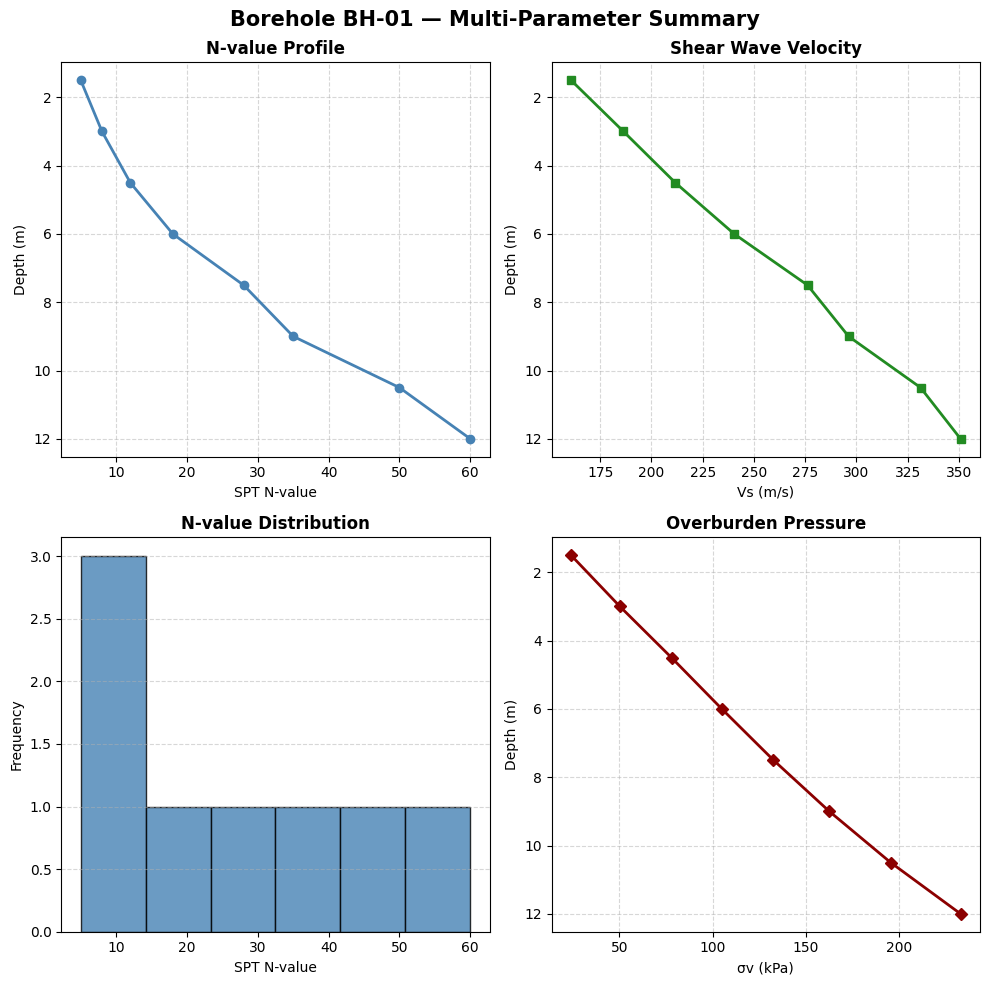

2x2 grid: each axes[row, col] is an independent subplot.
σv at 12m: 233.2 kPa


In [3]:
# ─────────────────────────────────────────────────────
# 2x2 SUBPLOT GRID — Four views of borehole data
# ─────────────────────────────────────────────────────

depth_m    = np.array([1.5, 3.0, 4.5, 6.0, 7.5, 9.0, 10.5, 12.0])
n_value    = np.array([5, 8, 12, 18, 28, 35, 50, 60])
vs_profile = 97 * (n_value ** 0.314)              # Vs from N
gamma      = np.array([16.0, 17.5, 18.5, 18.0, 18.5, 20.0, 22.0, 25.0])

# Overburden pressure: cumulative sum of gamma * layer thickness
layer_thick = np.diff(depth_m, prepend=0)
sigma_v     = np.cumsum(gamma * layer_thick)

fig, axes = plt.subplots(2, 2, figsize=(10, 10))

# ---- Top-left: N-value profile ----
axes[0, 0].plot(n_value, depth_m, 'o-', color='steelblue', linewidth=2)
axes[0, 0].set_xlabel('SPT N-value')
axes[0, 0].set_ylabel('Depth (m)')
axes[0, 0].set_title('N-value Profile', fontweight='bold')
axes[0, 0].invert_yaxis()
axes[0, 0].grid(True, linestyle='--', alpha=0.5)

# ---- Top-right: Vs profile ----
axes[0, 1].plot(vs_profile, depth_m, 's-', color='forestgreen', linewidth=2)
axes[0, 1].set_xlabel('Vs (m/s)')
axes[0, 1].set_ylabel('Depth (m)')
axes[0, 1].set_title('Shear Wave Velocity', fontweight='bold')
axes[0, 1].invert_yaxis()
axes[0, 1].grid(True, linestyle='--', alpha=0.5)

# ---- Bottom-left: N-value histogram ----
axes[1, 0].hist(n_value, bins=6, color='steelblue', edgecolor='black', alpha=0.8)
axes[1, 0].set_xlabel('SPT N-value')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].set_title('N-value Distribution', fontweight='bold')
axes[1, 0].grid(axis='y', linestyle='--', alpha=0.5)

# ---- Bottom-right: Overburden pressure ----
axes[1, 1].plot(sigma_v, depth_m, 'D-', color='darkred', linewidth=2)
axes[1, 1].set_xlabel('\u03c3v (kPa)')
axes[1, 1].set_ylabel('Depth (m)')
axes[1, 1].set_title('Overburden Pressure', fontweight='bold')
axes[1, 1].invert_yaxis()
axes[1, 1].grid(True, linestyle='--', alpha=0.5)

fig.suptitle('Borehole BH-01 \u2014 Multi-Parameter Summary',
             fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

print("2x2 grid: each axes[row, col] is an independent subplot.")
print(f"\u03c3v at 12m: {sigma_v[-1]:.1f} kPa")

---

## Part 3: Customizing Colors, Markers, and Line Styles

Professional geotechnical plots use consistent color schemes:

| Soil Type | Typical Color | Hex Code |
|-----------|--------------|----------|
| Fill | Dark brown | `#654321` |
| Sand | Yellow/tan | `#F4D03F` |
| Silty Sand | Olive | `#D4AC0D` |
| Clay | Brown | `#A0522D` |
| Gravel | Gray | `#808080` |
| Bedrock | Dark gray | `#505050` |

Matplotlib accepts colors as: named (`'steelblue'`), hex (`'#2196F3'`), RGB tuple (`(0.13, 0.59, 0.95)`), or single letter (`'b'` for blue).

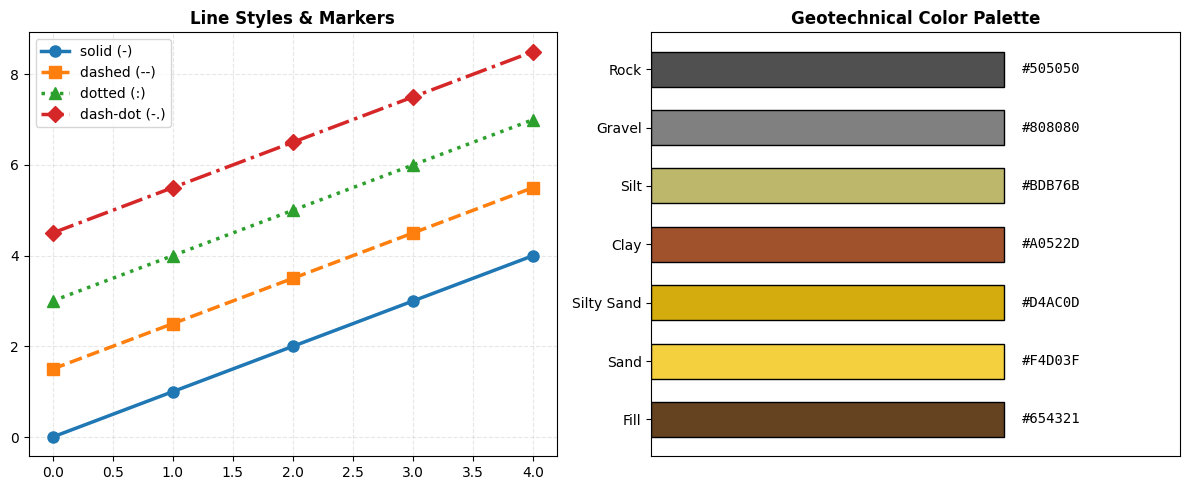

Use consistent colors for soil types across all project figures.


In [4]:
# ─────────────────────────────────────────────────────
# COLOR AND MARKER REFERENCE — Geotechnical palette
# ─────────────────────────────────────────────────────

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# ---- Left: Line style reference ----
styles = [('-', 'solid'), ('--', 'dashed'), (':', 'dotted'), ('-.', 'dash-dot')]
markers = ['o', 's', '^', 'D', 'v', 'P', '*', 'X']
x = np.arange(5)

for i, (ls, name) in enumerate(styles):
    ax1.plot(x, x + i * 1.5, linestyle=ls, linewidth=2.5,
             marker=markers[i], markersize=8, label=f"{name} ({ls})")

ax1.set_title('Line Styles & Markers', fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, linestyle='--', alpha=0.3)

# ---- Right: Geotechnical color palette ----
soil_colors = {
    'Fill':       '#654321',
    'Sand':       '#F4D03F',
    'Silty Sand': '#D4AC0D',
    'Clay':       '#A0522D',
    'Silt':       '#BDB76B',
    'Gravel':     '#808080',
    'Rock':       '#505050',
}

y_pos = np.arange(len(soil_colors))
ax2.barh(y_pos, [1]*len(soil_colors),
         color=list(soil_colors.values()), edgecolor='black', height=0.6)
ax2.set_yticks(y_pos)
ax2.set_yticklabels(list(soil_colors.keys()))
ax2.set_title('Geotechnical Color Palette', fontweight='bold')
ax2.set_xlim(0, 1.5)

# Add hex codes as text
for i, (name, color) in enumerate(soil_colors.items()):
    ax2.text(1.05, i, color, va='center', fontfamily='monospace', fontsize=10)

ax2.set_xticks([])

plt.tight_layout()
plt.show()

print("Use consistent colors for soil types across all project figures.")

---

## Part 4: Annotations and Text Boxes

Annotations add **context** to plots — labeling critical layers, marking the water table, or highlighting anomalies.

| Function | Purpose |
|----------|--------|
| `ax.annotate(text, xy, xytext, arrowprops)` | Text with arrow pointing to data |
| `ax.text(x, y, text, bbox)` | Floating text box at coordinates |
| `ax.axhline()` / `ax.axvline()` | Horizontal / vertical reference lines |
| `ax.axhspan()` / `ax.axvspan()` | Shaded horizontal / vertical bands |

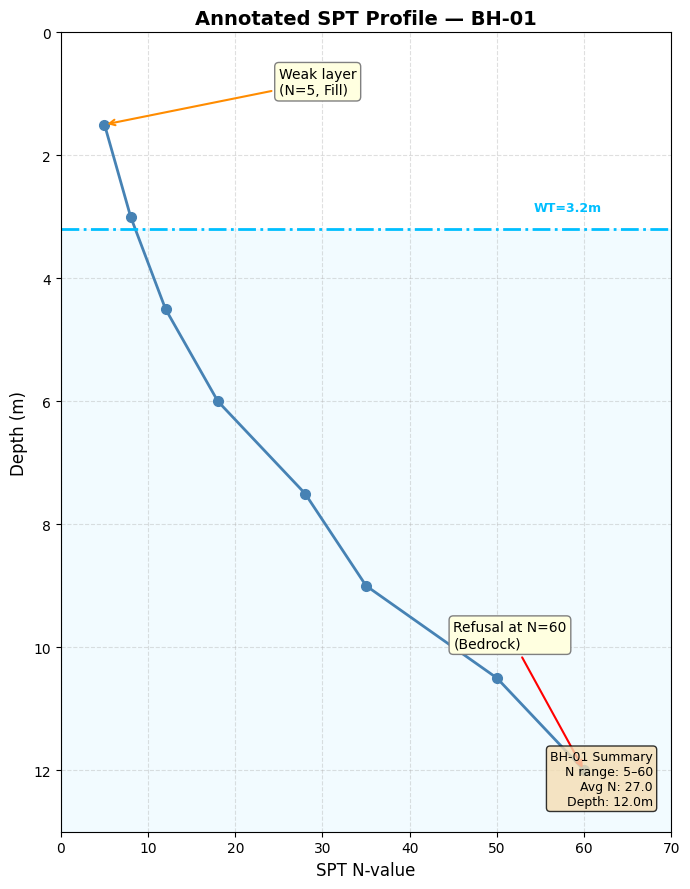

ax.annotate() uses arrowprops to point at data features.
ax.text() with transform=ax.transAxes positions text relative to the axes.
  (0,0) = bottom-left corner, (1,1) = top-right corner.


In [5]:
# ─────────────────────────────────────────────────────
# ANNOTATIONS — Labeling critical features
# ─────────────────────────────────────────────────────

depth_m = [1.5, 3.0, 4.5, 6.0, 7.5, 9.0, 10.5, 12.0]
n_value = [5, 8, 12, 18, 28, 35, 50, 60]
water_table = 3.2

fig, ax = plt.subplots(figsize=(7, 9))

ax.plot(n_value, depth_m, 'o-', color='steelblue', linewidth=2, markersize=7)
ax.invert_yaxis()
ax.set_xlim(0, 70)
ax.set_ylim(13, 0)

# ---- Annotate with arrow ----
ax.annotate('Refusal at N=60\n(Bedrock)',
            xy=(60, 12.0),              # point to annotate
            xytext=(45, 10.0),          # text position
            fontsize=10,
            arrowprops=dict(arrowstyle='->', color='red', lw=1.5),
            bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow',
                      edgecolor='gray'))

# ---- Annotate weak layer ----
ax.annotate('Weak layer\n(N=5, Fill)',
            xy=(5, 1.5),
            xytext=(25, 1.0),
            fontsize=10,
            arrowprops=dict(arrowstyle='->', color='darkorange', lw=1.5),
            bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow',
                      edgecolor='gray'))

# ---- Water table with shading ----
ax.axhline(y=water_table, color='deepskyblue', linestyle='-.', linewidth=2)
ax.axhspan(water_table, 13, alpha=0.05, color='deepskyblue')
ax.text(62, water_table - 0.3, f'WT={water_table}m',
        fontsize=9, color='deepskyblue', fontweight='bold',
        ha='right')

# ---- Text box with summary stats ----
stats_text = (f'BH-01 Summary\n'
              f'N range: {min(n_value)}\u2013{max(n_value)}\n'
              f'Avg N: {np.mean(n_value):.1f}\n'
              f'Depth: {max(depth_m)}m')
ax.text(0.97, 0.03, stats_text, transform=ax.transAxes,
        fontsize=9, verticalalignment='bottom', horizontalalignment='right',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

ax.set_xlabel('SPT N-value', fontsize=12)
ax.set_ylabel('Depth (m)', fontsize=12)
ax.set_title('Annotated SPT Profile \u2014 BH-01', fontsize=14, fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

print("ax.annotate() uses arrowprops to point at data features.")
print("ax.text() with transform=ax.transAxes positions text relative to the axes.")
print("  (0,0) = bottom-left corner, (1,1) = top-right corner.")

---

## Part 5: Axis Limits, Ticks, and Formatting

Fine control over axes makes plots readable and professional:

| Method | Purpose |
|--------|--------|
| `ax.set_xlim(min, max)` | Set x-axis range |
| `ax.set_ylim(min, max)` | Set y-axis range |
| `ax.set_xticks([...])` | Set tick positions |
| `ax.set_xticklabels([...])` | Custom tick labels |
| `ax.tick_params()` | Font size, rotation, padding |

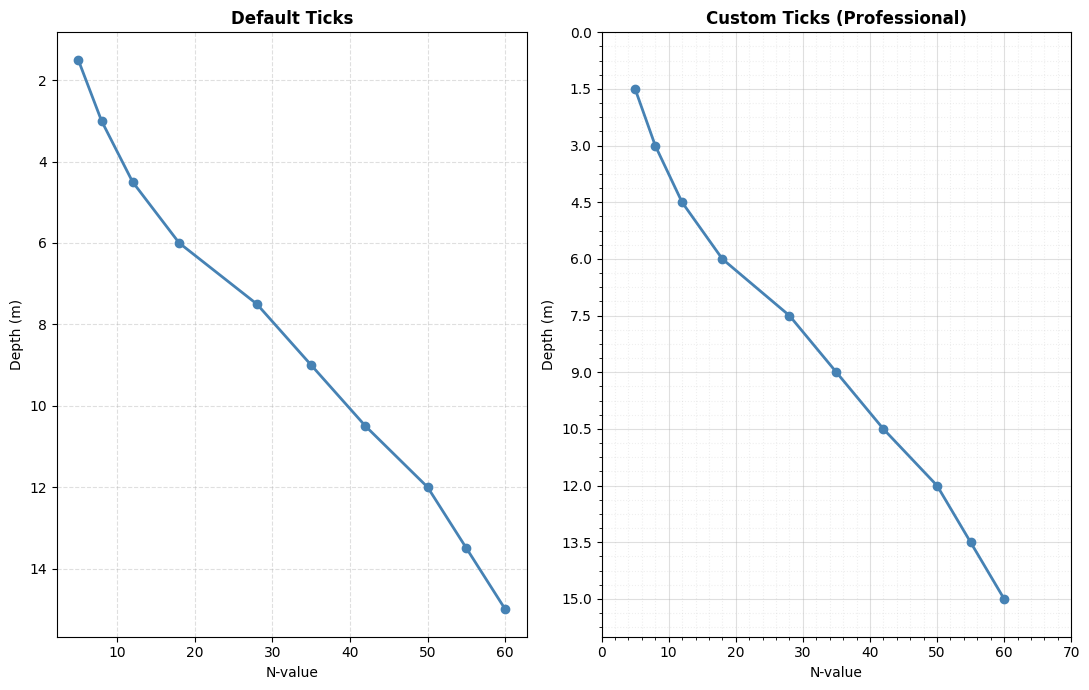

Custom ticks aligned to SPT test interval (every 1.5m) improve readability.
Minor gridlines help read intermediate values.


In [6]:
# ─────────────────────────────────────────────────────
# AXIS FORMATTING — Professional tick control
# ─────────────────────────────────────────────────────

depth_m = np.array([1.5, 3.0, 4.5, 6.0, 7.5, 9.0, 10.5, 12.0, 13.5, 15.0])
n_value = np.array([5, 8, 12, 18, 28, 35, 42, 50, 55, 60])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 7))

# ---- Left: Default ticks (auto) ----
ax1.plot(n_value, depth_m, 'o-', color='steelblue', linewidth=2)
ax1.invert_yaxis()
ax1.set_title('Default Ticks', fontweight='bold', fontsize=12)
ax1.set_xlabel('N-value')
ax1.set_ylabel('Depth (m)')
ax1.grid(True, linestyle='--', alpha=0.4)

# ---- Right: Custom ticks (professional) ----
ax2.plot(n_value, depth_m, 'o-', color='steelblue', linewidth=2)
ax2.invert_yaxis()
ax2.set_title('Custom Ticks (Professional)', fontweight='bold', fontsize=12)
ax2.set_xlabel('N-value')
ax2.set_ylabel('Depth (m)')

# Custom x-axis: every 10 blows
ax2.set_xlim(0, 70)
ax2.set_xticks(np.arange(0, 71, 10))

# Custom y-axis: every 1.5m (matches SPT interval)
ax2.set_ylim(16, 0)
ax2.set_yticks(np.arange(0, 16.5, 1.5))

# Minor grid for readability
ax2.grid(True, which='major', linestyle='-', alpha=0.4)
ax2.grid(True, which='minor', linestyle=':', alpha=0.2)
ax2.minorticks_on()

# Tick label formatting
ax2.tick_params(axis='both', labelsize=10)

plt.tight_layout()
plt.show()

print("Custom ticks aligned to SPT test interval (every 1.5m) improve readability.")
print("Minor gridlines help read intermediate values.")

---

## Part 6: Saving Figures — `plt.savefig()`

For reports and publications, you need to export figures as image files.

| Format | Use Case | Syntax |
|--------|---------|--------|
| PNG | Web, presentations | `plt.savefig('plot.png', dpi=300)` |
| PDF | Reports, papers | `plt.savefig('plot.pdf')` |
| SVG | Scalable web graphics | `plt.savefig('plot.svg')` |

**Important:** Call `savefig()` BEFORE `show()`, because `show()` clears the figure in some backends.

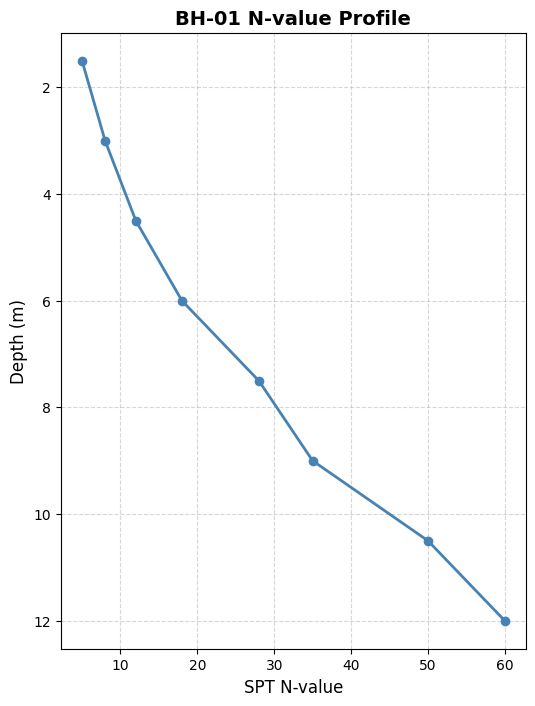

Saved: spt_profile_bh01.png
  dpi=300         : high resolution for print
  bbox_inches='tight' : crop whitespace
  facecolor='white'   : white background (not transparent)


In [7]:
# ─────────────────────────────────────────────────────
# SAVING FIGURES — Export for reports
# ─────────────────────────────────────────────────────

depth_m = [1.5, 3.0, 4.5, 6.0, 7.5, 9.0, 10.5, 12.0]
n_value = [5, 8, 12, 18, 28, 35, 50, 60]

fig, ax = plt.subplots(figsize=(6, 8))
ax.plot(n_value, depth_m, 'o-', color='steelblue', linewidth=2)
ax.invert_yaxis()
ax.set_xlabel('SPT N-value', fontsize=12)
ax.set_ylabel('Depth (m)', fontsize=12)
ax.set_title('BH-01 N-value Profile', fontsize=14, fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.5)

# Save BEFORE show
fig.savefig('spt_profile_bh01.png', dpi=300, bbox_inches='tight',
            facecolor='white', edgecolor='none')

plt.show()

print("Saved: spt_profile_bh01.png")
print("  dpi=300         : high resolution for print")
print("  bbox_inches='tight' : crop whitespace")
print("  facecolor='white'   : white background (not transparent)")

---

## Part 7: Soil Stratigraphy Column

Before building the final summary sheet, let's learn how to draw a **soil stratigraphy column** — colored blocks representing each soil layer. This uses `ax.barh()` or `ax.fill_betweenx()` with the geotechnical color palette.

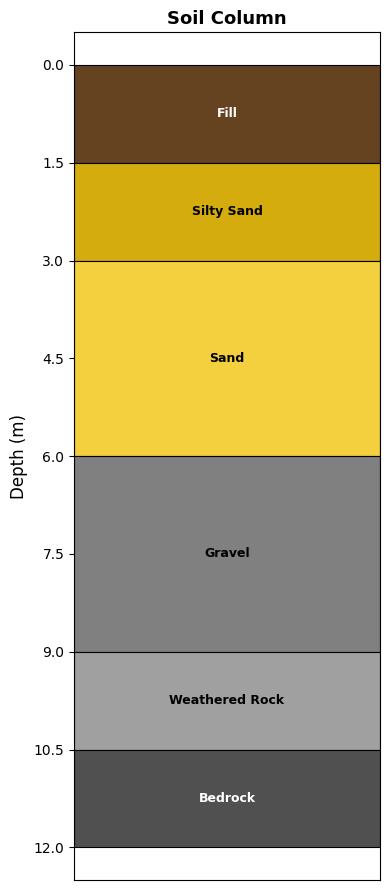

Soil column uses barh() to draw colored blocks for each layer.
This will become one panel in our final summary sheet.


In [8]:
# ─────────────────────────────────────────────────────
# SOIL STRATIGRAPHY COLUMN — Colored layer blocks
# ─────────────────────────────────────────────────────

# Layer boundaries and soil types
layer_top    = [0.0,  1.5,  3.0,  6.0,  9.0, 10.5]
layer_bottom = [1.5,  3.0,  6.0,  9.0, 10.5, 12.0]
soil_names   = ['Fill', 'Silty Sand', 'Sand', 'Gravel',
                'Weathered Rock', 'Bedrock']

color_map = {
    'Fill':           '#654321',
    'Silty Sand':     '#D4AC0D',
    'Sand':           '#F4D03F',
    'Gravel':         '#808080',
    'Weathered Rock': '#A0A0A0',
    'Bedrock':        '#505050',
}

fig, ax = plt.subplots(figsize=(4, 9))

for top, bot, soil in zip(layer_top, layer_bottom, soil_names):
    thickness = bot - top
    color = color_map.get(soil, '#CCCCCC')
    # Draw filled rectangle
    ax.barh(top + thickness/2, 1, height=thickness,
            color=color, edgecolor='black', linewidth=0.8)
    # Label at center of layer
    ax.text(0.5, top + thickness/2, soil,
            ha='center', va='center', fontsize=9, fontweight='bold',
            color='white' if soil in ['Fill', 'Bedrock'] else 'black')

ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_ylim(12.5, -0.5)
ax.set_ylabel('Depth (m)', fontsize=12)
ax.set_title('Soil Column', fontsize=13, fontweight='bold')
ax.set_xticks([])  # No x-axis ticks needed
ax.set_yticks(np.arange(0, 13, 1.5))

plt.tight_layout()
plt.show()

print("Soil column uses barh() to draw colored blocks for each layer.")
print("This will become one panel in our final summary sheet.")

---

## Part 8: Complete Application — Borehole Summary Sheet

Now we combine everything into a **2x2 panel borehole summary sheet**:

| Panel | Content |
|-------|--------|
| (0,0) | N-value depth profile |
| (0,1) | Soil stratigraphy column |
| (1,0) | Vs depth profile |
| (1,1) | Overburden pressure profile |

All panels share the same depth axis for direct comparison.

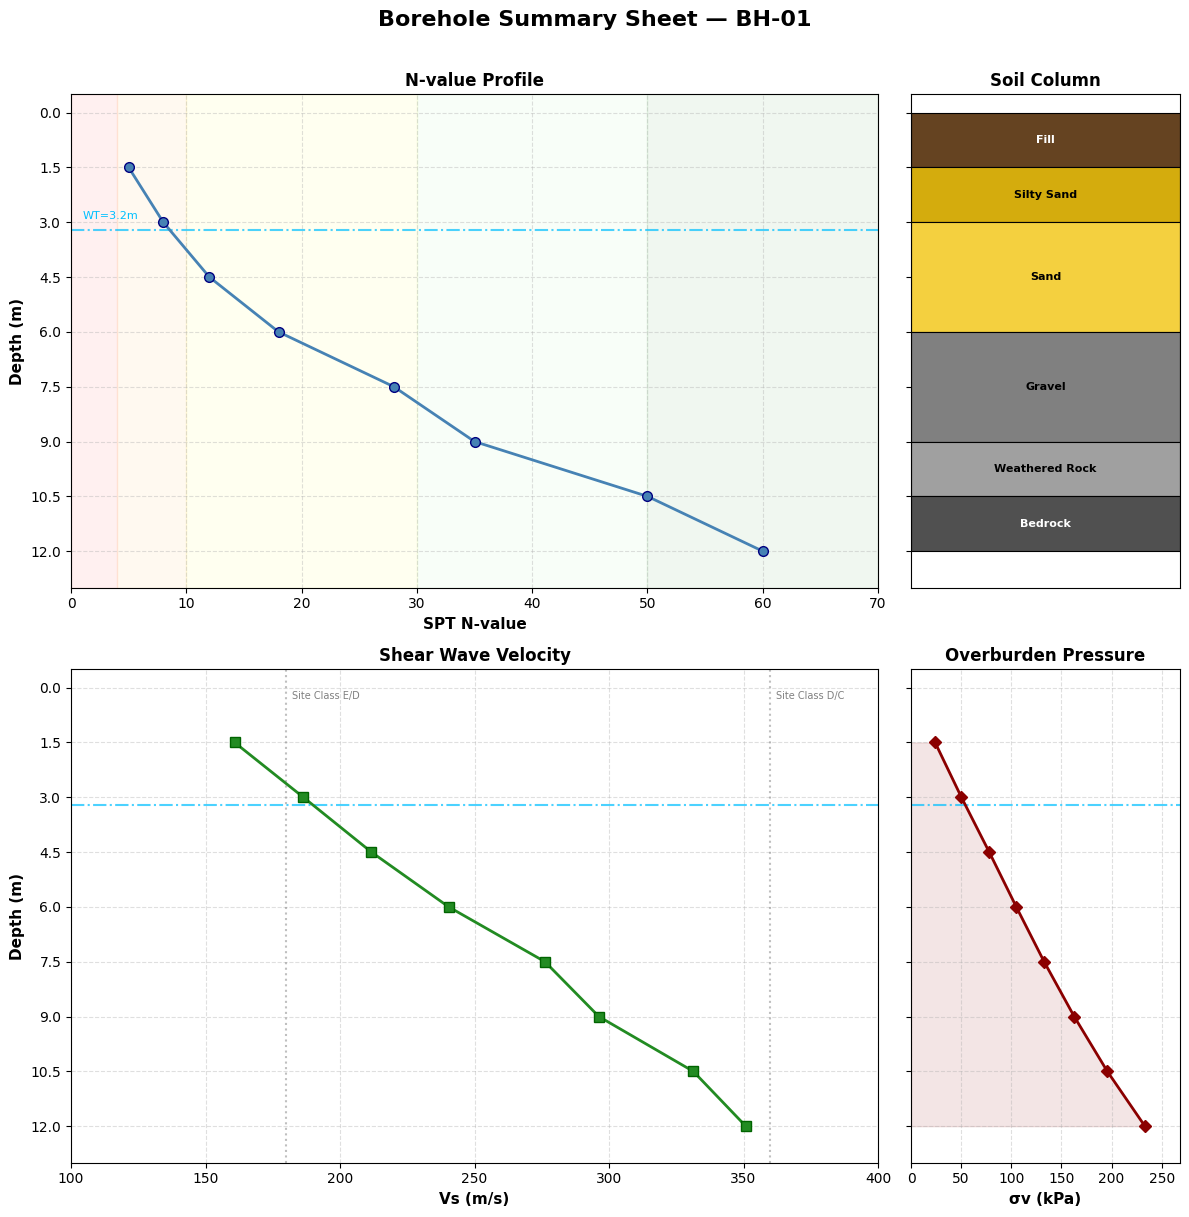

Borehole: BH-01
Depth: 1.5–12.0 m | WT: 3.2 m
N range: 5–60
Vs range: 161–351 m/s
σv at 12.0m: 233.2 kPa

This 2x2 layout is the standard borehole summary sheet format.


In [9]:
# ═════════════════════════════════════════════════
# COMPLETE: BOREHOLE SUMMARY SHEET (2x2 PANELS)
# ═════════════════════════════════════════════════

# ---- Borehole data ----
bh_id = 'BH-01'
water_table = 3.2

depth_m   = np.array([1.5, 3.0, 4.5, 6.0, 7.5, 9.0, 10.5, 12.0])
n_value   = np.array([5, 8, 12, 18, 28, 35, 50, 60])
vs_values = 97 * (n_value ** 0.314)
gamma     = np.array([16.0, 17.5, 18.5, 18.0, 18.5, 20.0, 22.0, 25.0])

# Overburden pressure
layer_thick = np.diff(depth_m, prepend=0)
sigma_v     = np.cumsum(gamma * layer_thick)

# Stratigraphy
layer_top    = [0.0,  1.5,  3.0,  6.0,  9.0, 10.5]
layer_bottom = [1.5,  3.0,  6.0,  9.0, 10.5, 12.0]
soil_names   = ['Fill', 'Silty Sand', 'Sand', 'Gravel',
                'Weathered Rock', 'Bedrock']
color_map = {
    'Fill': '#654321', 'Silty Sand': '#D4AC0D', 'Sand': '#F4D03F',
    'Gravel': '#808080', 'Weathered Rock': '#A0A0A0', 'Bedrock': '#505050',
}

# ---- Create figure with custom width ratios ----
fig, axes = plt.subplots(2, 2, figsize=(12, 12),
                          gridspec_kw={'width_ratios': [3, 1]})

# All depth panels share the same y-range
y_min, y_max = 13, -0.5

# ══════════════════════════════════════════════
# PANEL (0,0): N-value Profile
# ══════════════════════════════════════════════
ax = axes[0, 0]
ax.plot(n_value, depth_m, 'o-', color='steelblue', linewidth=2,
        markersize=7, markeredgecolor='navy', zorder=5)

# Density bands
ax.axvspan(0, 4, alpha=0.06, color='red')
ax.axvspan(4, 10, alpha=0.06, color='orange')
ax.axvspan(10, 30, alpha=0.06, color='yellow')
ax.axvspan(30, 50, alpha=0.06, color='lightgreen')
ax.axvspan(50, 70, alpha=0.06, color='green')

ax.axhline(y=water_table, color='deepskyblue', linestyle='-.', linewidth=1.5, alpha=0.7)
ax.text(1, water_table - 0.3, f'WT={water_table}m', fontsize=8, color='deepskyblue')

ax.set_xlim(0, 70)
ax.set_ylim(y_min, y_max)
ax.set_xlabel('SPT N-value', fontsize=11, fontweight='bold')
ax.set_ylabel('Depth (m)', fontsize=11, fontweight='bold')
ax.set_title('N-value Profile', fontsize=12, fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.4)
ax.set_yticks(np.arange(0, 13.5, 1.5))

# ══════════════════════════════════════════════
# PANEL (0,1): Soil Stratigraphy Column
# ══════════════════════════════════════════════
ax = axes[0, 1]
for top, bot, soil in zip(layer_top, layer_bottom, soil_names):
    thickness = bot - top
    color = color_map.get(soil, '#CCCCCC')
    ax.barh(top + thickness/2, 1, height=thickness,
            color=color, edgecolor='black', linewidth=0.8)
    ax.text(0.5, top + thickness/2, soil,
            ha='center', va='center', fontsize=8, fontweight='bold',
            color='white' if soil in ['Fill', 'Bedrock'] else 'black')

ax.set_xlim(0, 1)
ax.set_ylim(y_min, y_max)
ax.set_xticks([])
ax.set_yticks(np.arange(0, 13.5, 1.5))
ax.set_yticklabels([])
ax.set_title('Soil Column', fontsize=12, fontweight='bold')

# ══════════════════════════════════════════════
# PANEL (1,0): Vs Profile
# ══════════════════════════════════════════════
ax = axes[1, 0]
ax.plot(vs_values, depth_m, 's-', color='forestgreen', linewidth=2,
        markersize=7, markeredgecolor='darkgreen', zorder=5)

# Vs classification lines
ax.axvline(x=180, color='gray', linestyle=':', alpha=0.5)
ax.text(182, 0.3, 'Site Class E/D', fontsize=7, color='gray')
ax.axvline(x=360, color='gray', linestyle=':', alpha=0.5)
ax.text(362, 0.3, 'Site Class D/C', fontsize=7, color='gray')

ax.axhline(y=water_table, color='deepskyblue', linestyle='-.', linewidth=1.5, alpha=0.7)

ax.set_xlim(100, 400)
ax.set_ylim(y_min, y_max)
ax.set_xlabel('Vs (m/s)', fontsize=11, fontweight='bold')
ax.set_ylabel('Depth (m)', fontsize=11, fontweight='bold')
ax.set_title('Shear Wave Velocity', fontsize=12, fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.4)
ax.set_yticks(np.arange(0, 13.5, 1.5))

# ══════════════════════════════════════════════
# PANEL (1,1): Overburden Pressure
# ══════════════════════════════════════════════
ax = axes[1, 1]
ax.plot(sigma_v, depth_m, 'D-', color='darkred', linewidth=2,
        markersize=6, zorder=5)
ax.fill_betweenx(depth_m, 0, sigma_v, alpha=0.1, color='darkred')

ax.axhline(y=water_table, color='deepskyblue', linestyle='-.', linewidth=1.5, alpha=0.7)

ax.set_xlim(0, max(sigma_v) * 1.15)
ax.set_ylim(y_min, y_max)
ax.set_xlabel('\u03c3v (kPa)', fontsize=11, fontweight='bold')
ax.set_yticks(np.arange(0, 13.5, 1.5))
ax.set_yticklabels([])
ax.set_title('Overburden Pressure', fontsize=12, fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.4)

# ---- Overall title ----
fig.suptitle(f'Borehole Summary Sheet \u2014 {bh_id}',
             fontsize=16, fontweight='bold', y=1.01)

plt.tight_layout()
plt.show()

print(f"Borehole: {bh_id}")
print(f"Depth: {depth_m[0]}\u2013{depth_m[-1]} m | WT: {water_table} m")
print(f"N range: {n_value.min()}\u2013{n_value.max()}")
print(f"Vs range: {vs_values.min():.0f}\u2013{vs_values.max():.0f} m/s")
print(f"\u03c3v at {depth_m[-1]}m: {sigma_v[-1]:.1f} kPa")
print("\nThis 2x2 layout is the standard borehole summary sheet format.")

---

## Practice Exercises

### Exercise 1: Side-by-side profiles
Create a `plt.subplots(1, 3)` figure showing N-value profiles for BH-01, BH-02, and BH-03 side by side with `sharey=True`. Use different colors for each.

### Exercise 2: Annotated profile
Take any N-value profile and add annotations for: (a) the weakest layer, (b) the strongest layer, and (c) the water table. Use `ax.annotate()` with arrows.

### Exercise 3: Save a figure
Create any geotechnical plot and save it as both PNG (300 dpi) and PDF. Verify the files were created.

In [10]:
# EXERCISE 1
# fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 7), sharey=True)
# ...

In [11]:
# EXERCISE 2
# fig, ax = plt.subplots(figsize=(7, 9))
# ax.annotate('Weakest layer', xy=(...), xytext=(...), ...)
# ...

In [12]:
# EXERCISE 3
# fig, ax = plt.subplots(figsize=(6, 8))
# ... build plot ...
# fig.savefig('my_plot.png', dpi=300, bbox_inches='tight')
# fig.savefig('my_plot.pdf', bbox_inches='tight')
# ...

---

## Key Takeaways

1. **`plt.subplots(nrows, ncols)`** creates multi-panel figures — essential for showing multiple data types on the same page with aligned depth axes.

2. **`sharey=True`** ensures all panels share the same y-axis scale, critical when comparing profiles across boreholes.

3. **`ax.annotate()`** with `arrowprops` points arrows at critical features — weak layers, refusal, water table — making plots self-explanatory.

4. **`plt.savefig()`** exports publication-quality figures. Always use `dpi=300` for print and `bbox_inches='tight'` to avoid clipped labels.

5. **Soil stratigraphy columns** can be built with `barh()` and a consistent color map — pair with N-value and Vs profiles for a complete borehole summary.

---

## How This Connects to ML

| Today's Concept | ML Equivalent |
|----------------|---------------|
| Subplots grid | Training curves: loss, accuracy, lr in one figure |
| Shared axes | Comparing train vs validation on same scale |
| Annotations | Marking best epoch, overfitting point |
| Color palettes | Class-specific colors in confusion matrices |
| savefig() | Exporting results for papers and reports |
| Custom ticks | Epoch numbers, feature names on axes |
| Text boxes | Displaying final metrics on the plot |

ML papers live and die by their figures. The subplot and annotation skills from today let you build the multi-panel results figures that reviewers expect.

---

*Day 024 of 100 — Subplots let one figure tell the whole story!*